In [65]:
from IPython.display import display, Markdown

display(Markdown("""
# Iris Flower Classification

## Oasis Infobyte Data Science Internship – Task 1

### Project Objective

The objective of this project is to classify Iris flowers into three species:

- Setosa
- Versicolor
- Virginica

Machine Learning algorithms are used to predict flower species based on their measurements.
"""))


# Iris Flower Classification

## Oasis Infobyte Data Science Internship – Task 1

### Project Objective

The objective of this project is to classify Iris flowers into three species:

- Setosa
- Versicolor
- Virginica

Machine Learning algorithms are used to predict flower species based on their measurements.


In [66]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [67]:
# Load the built-in Iris dataset

iris = load_iris()

# Store features and target
X = iris.data
y = iris.target

# Display dataset information
print("Dataset Loaded Successfully!")
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)
print("Flower Species:", iris.target_names)
print("Feature Names:", iris.feature_names)

Dataset Loaded Successfully!
Feature Shape: (150, 4)
Target Shape: (150,)
Flower Species: ['setosa' 'versicolor' 'virginica']
Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [68]:
# Check dataset shape
print("Dataset Shape:", X.shape)

# Check feature data types
print("\nData Types:")
print(X.dtype)

# Check missing values
print("\nMissing Values:")
print(np.isnan(X).sum())

# Display first 5 records
print("\nFirst 5 Records:")
print(X[:5])

Dataset Shape: (150, 4)

Data Types:
float64

Missing Values:
0

First 5 Records:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


In [69]:
# Calculate descriptive statistics

print("Mean of each feature:")
print(np.mean(X, axis=0))

print("\nMinimum values:")
print(np.min(X, axis=0))

print("\nMaximum values:")
print(np.max(X, axis=0))

print("\nStandard Deviation:")
print(np.std(X, axis=0))

Mean of each feature:
[5.84333333 3.05733333 3.758      1.19933333]

Minimum values:
[4.3 2.  1.  0.1]

Maximum values:
[7.9 4.4 6.9 2.5]

Standard Deviation:
[0.82530129 0.43441097 1.75940407 0.75969263]


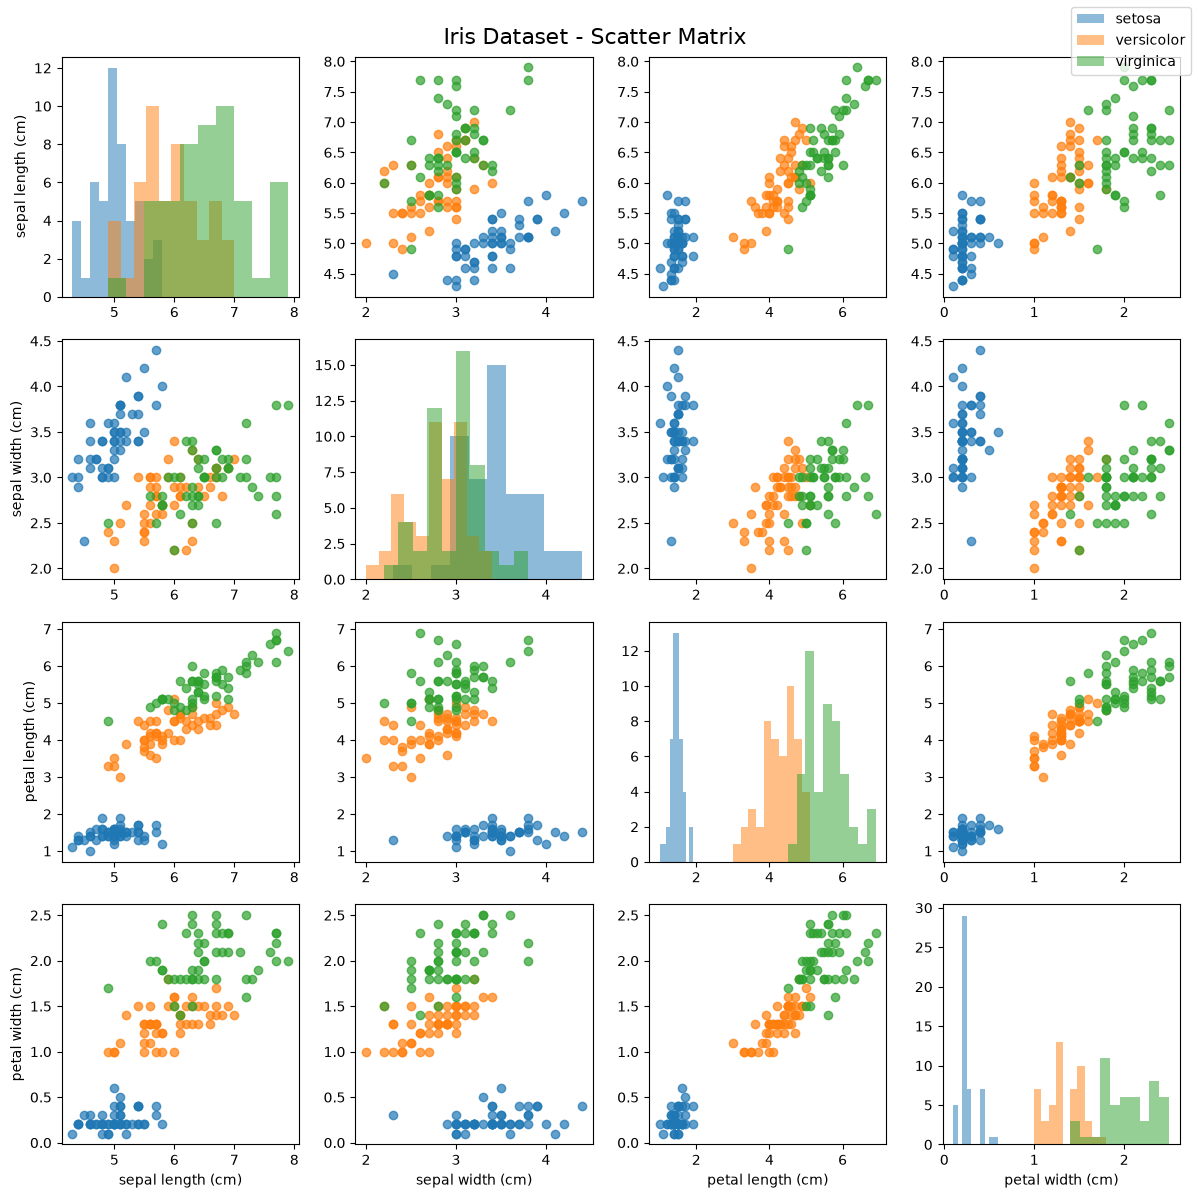

In [70]:
# Scatter Matrix without Pandas

from matplotlib import colors

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i in range(4):
    for j in range(4):
        ax = axes[i, j]

        if i == j:
            for species in range(3):
                ax.hist(
                    X[y == species, i],
                    alpha=0.5,
                    label=iris.target_names[species]
                )
        else:
            for species in range(3):
                ax.scatter(
                    X[y == species, j],
                    X[y == species, i],
                    label=iris.target_names[species],
                    alpha=0.7
                )

        if i == 3:
            ax.set_xlabel(iris.feature_names[j])

        if j == 0:
            ax.set_ylabel(iris.feature_names[i])

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")

plt.suptitle("Iris Dataset - Scatter Matrix", fontsize=16)
plt.tight_layout()
plt.show()


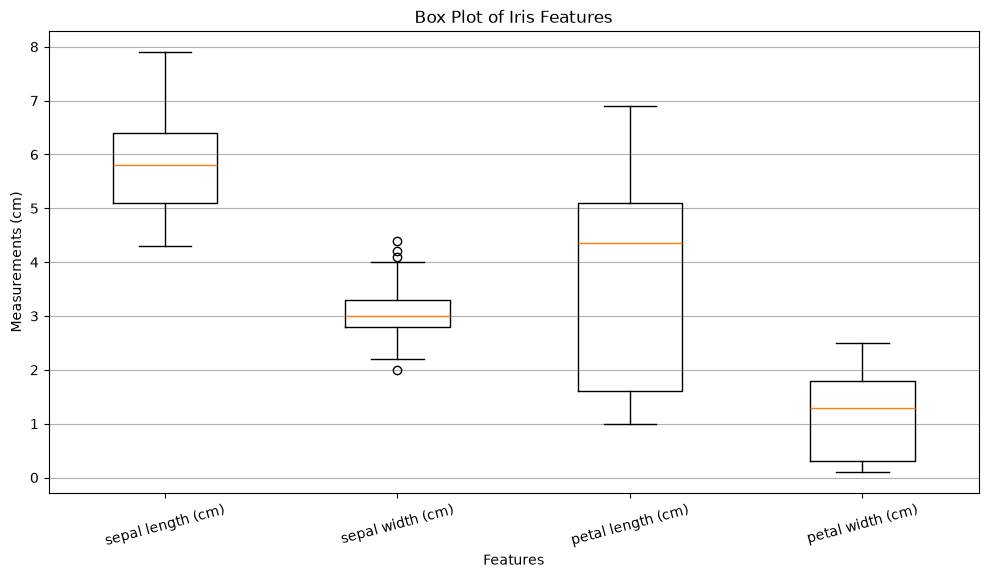

In [71]:
# Box plots for all four Iris features

plt.figure(figsize=(12, 6))

plt.boxplot(
    [X[:, i] for i in range(4)],
    tick_labels=iris.feature_names
)

plt.title("Box Plot of Iris Features")
plt.xlabel("Features")
plt.ylabel("Measurements (cm)")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()

In [72]:
# Feature Selection Discussion

print("Feature Selection Analysis")
print("--------------------------")

for i, feature in enumerate(iris.feature_names):
    print(f"{feature}:")
    for species in range(3):
        mean_value = np.mean(X[y == species, i])
        print(f"  {iris.target_names[species]}: {mean_value:.2f} cm")
    print()

print("Conclusion:")
print("Petal length and petal width are highly discriminative features.")
print("They help distinguish the three Iris flower species.")

Feature Selection Analysis
--------------------------
sepal length (cm):
  setosa: 5.01 cm
  versicolor: 5.94 cm
  virginica: 6.59 cm

sepal width (cm):
  setosa: 3.43 cm
  versicolor: 2.77 cm
  virginica: 2.97 cm

petal length (cm):
  setosa: 1.46 cm
  versicolor: 4.26 cm
  virginica: 5.55 cm

petal width (cm):
  setosa: 0.25 cm
  versicolor: 1.33 cm
  virginica: 2.03 cm

Conclusion:
Petal length and petal width are highly discriminative features.
They help distinguish the three Iris flower species.


In [73]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and Testing Split Completed!")
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training and Testing Split Completed!
Training Samples: 120
Testing Samples: 30
Training Target: (120,)
Testing Target: (30,)


In [74]:
# Initialize Machine Learning models

log_model = LogisticRegression(max_iter=200)
tree_model = DecisionTreeClassifier(random_state=42)

# Train Logistic Regression
log_model.fit(X_train, y_train)

# Train Decision Tree
tree_model.fit(X_train, y_train)

print("Both Models Trained Successfully!")

Both Models Trained Successfully!


In [75]:
# Make predictions using both models

log_predictions = log_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

# Calculate accuracy

log_accuracy = accuracy_score(y_test, log_predictions)
tree_accuracy = accuracy_score(y_test, tree_predictions)

print("Model Accuracy Comparison")
print("-------------------------")
print(f"Logistic Regression: {log_accuracy * 100:.2f}%")
print(f"Decision Tree: {tree_accuracy * 100:.2f}%")

Model Accuracy Comparison
-------------------------
Logistic Regression: 96.67%
Decision Tree: 93.33%


In [76]:
# Evaluate Logistic Regression Model

print("LOGISTIC REGRESSION EVALUATION")
print("--------------------------------")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, log_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    log_predictions,
    target_names=iris.target_names
))


# Evaluate Decision Tree Model

print("\nDECISION TREE EVALUATION")
print("--------------------------------")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tree_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tree_predictions,
    target_names=iris.target_names
))

LOGISTIC REGRESSION EVALUATION
--------------------------------

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


DECISION TREE EVALUATION
--------------------------------

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted a

In [77]:
# Select the best-performing model

if log_accuracy > tree_accuracy:
    best_model = log_model
    best_model_name = "Logistic Regression"
    best_accuracy = log_accuracy
else:
    best_model = tree_model
    best_model_name = "Decision Tree"

print("BEST MODEL SELECTION")
print("--------------------")
print("Best Model:", best_model_name)
print(f"Best Accuracy: {best_accuracy * 100:.2f}%")
print("\nReason:")
print("Logistic Regression achieved higher accuracy than Decision Tree.")

BEST MODEL SELECTION
--------------------
Best Model: Logistic Regression
Best Accuracy: 96.67%

Reason:
Logistic Regression achieved higher accuracy than Decision Tree.


In [78]:
# Save the best-performing model

import os
import joblib

# Create outputs folder if it does not exist
os.makedirs("outputs", exist_ok=True)

# Save model
joblib.dump(best_model, "outputs/best_iris_model.pkl")

print("Best Model Saved Successfully!")
print("Model Name:", best_model_name)
print("Saved Location: outputs/best_iris_model.pkl")

Best Model Saved Successfully!
Model Name: Logistic Regression
Saved Location: outputs/best_iris_model.pkl


In [79]:
# Final Project Conclusion

print("IRIS FLOWER CLASSIFICATION - PROJECT CONCLUSION")
print("------------------------------------------------")

print("1. Iris dataset contains 150 samples and 4 features.")
print("2. Exploratory Data Analysis was performed.")
print("3. Scatter matrix and box plots were generated.")
print("4. Two classification models were trained.")
print("5. Logistic Regression achieved 96.67% accuracy.")
print("6. Decision Tree achieved 93.33% accuracy.")
print("7. Logistic Regression was selected as the best model.")

print("\nProject Completed Successfully!")

IRIS FLOWER CLASSIFICATION - PROJECT CONCLUSION
------------------------------------------------
1. Iris dataset contains 150 samples and 4 features.
2. Exploratory Data Analysis was performed.
3. Scatter matrix and box plots were generated.
4. Two classification models were trained.
5. Logistic Regression achieved 96.67% accuracy.
6. Decision Tree achieved 93.33% accuracy.
7. Logistic Regression was selected as the best model.

Project Completed Successfully!


In [80]:
from IPython.display import display, Markdown

display(Markdown("""
### Feature Selection – Analysis

Petal length and petal width are the most discriminative features
for Iris flower classification.

1. Petal Length: Helps distinguish Setosa, Versicolor and Virginica.
2. Petal Width: Shows clear differences between flower species.
3. Sepal Length: Provides additional classification information.
4. Sepal Width: Is useful, but has more overlap between species.

Conclusion:
Petal measurements are generally more useful than sepal measurements
for distinguishing Iris flower species.
"""))


### Feature Selection – Analysis

Petal length and petal width are the most discriminative features
for Iris flower classification.

1. Petal Length: Helps distinguish Setosa, Versicolor and Virginica.
2. Petal Width: Shows clear differences between flower species.
3. Sepal Length: Provides additional classification information.
4. Sepal Width: Is useful, but has more overlap between species.

Conclusion:
Petal measurements are generally more useful than sepal measurements
for distinguishing Iris flower species.
